# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/begs44/flyrank-ml/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

**Question:** Which pages should a content editor review first? Unit = one page; output = a ranked weekly list of 50 pages with a reason code and an action. Label = impressions fell more than 20% (last 30 days vs the 30 days before), base rate 0.54. Full write-up: the deployed paper.

In [ ]:
import os, json
import pandas as pd
import numpy as np
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score

SEED = 42
url = "https://raw.githubusercontent.com/begs44/flyrank-ml/main/data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(url)
df["target_decay"] = (df["trend_direction"] == "down").astype(int)
base = df["target_decay"].mean()

# ---- Same Week-5 feature set ----
df["avg_position"] = df["avg_position"].replace(0, np.nan)
df["has_word_count"] = df["word_count"].notna().astype(int)
df["has_keyword_data"] = df["search_volume"].notna().astype(int)
for c in ["impressions_90d", "clicks_90d", "sessions_90d", "ai_sessions_90d"]:
    df[f"log_{c}"] = np.log1p(df[c])
NUMERIC = ["search_volume", "competition", "cpc", "word_count",
           "log_impressions_90d", "log_clicks_90d", "log_sessions_90d", "log_ai_sessions_90d",
           "days_with_impressions", "days_with_sessions", "content_age_days", "days_since_last_update",
           "ctr", "avg_position", "engagement_rate", "scroll_rate", "ai_traffic_pct",
           "has_word_count", "has_keyword_data"]
CATEGORICAL = ["content_type", "main_intent", "competition_level"]
df[CATEGORICAL] = df[CATEGORICAL].fillna("unknown")
y = df["target_decay"]

print(f"Question: which pages should an editor review first? Unit = one page. Label = impressions fell >20% "
      f"(last 30d vs previous 30d). Base rate: {base:.3f}")

Question: which pages should an editor review first? Unit = one page. Label = impressions fell >20% (last 30d vs previous 30d). Base rate: 0.542


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

**Data:** the FlyRank ML Internship starter slice: 30,000 pseudonymized pages, 32 clients, trailing 90-day metrics, content aged 90–564 days. The full warehouse release was explored in Week 3, but every number here comes from this slice. Excluded: label sources (`trend_*`, `*_last_30d`, `*_prev_30d`), IDs (grouping only) and tier buckets. No client names, URLs or queries.

In [ ]:
print(f"Rows: {len(df):,} pages | clients: {df['client_id'].nunique()} | content types: {df['content_type'].nunique()}")
print(f"Content age: {df['content_age_days'].min()}-{df['content_age_days'].max()} days | metrics: trailing 90-day window")
print(f"avg_position = 0 ('no data') -> treated as missing: {df['avg_position'].isna().sum():,} rows")
print(f"word_count missing: {df['word_count'].isna().sum():,} rows (keyword articles only) -> has_word_count flag, no fill with 0")
print(f"Pages per client: median {df['client_id'].value_counts().median():.0f}, largest {df['client_id'].value_counts().max():,}")
print("Excluded from features: trend_direction, trend_pct, *_last_30d, *_prev_30d (label sources), content_id, client_id (IDs), tier buckets (existing-system flags)")

Rows: 30,000 pages | clients: 32 | content types: 3
Content age: 90-564 days | metrics: trailing 90-day window
avg_position = 0 ('no data') -> treated as missing: 1,205 rows
word_count missing: 7,699 rows (keyword articles only) -> has_word_count flag, no fill with 0
Pages per client: median 567, largest 7,008
Excluded from features: trend_direction, trend_pct, *_last_30d, *_prev_30d (label sources), content_id, client_id (IDs), tier buckets (existing-system flags)


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

**Methodology:** baseline = the Week-4 CTR-for-position rule; models = Logistic Regression and Gradient Boosting on 19 numeric + 3 categorical features. Validation = 5-fold cross-validation grouped by client (the main design), plus a random split for the before/after comparison. Metric = P@50, shown next to the base rate. Leakage guard, deliberate-leak test and window check run below. Seed 42.

In [ ]:
def prep(scale, num_cols=None):
    num_cols = num_cols or NUMERIC
    num = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()) if scale else SimpleImputer(strategy="median")
    return make_column_transformer((num, num_cols), (OneHotEncoder(handle_unknown="ignore"), CATEGORICAL))

def make_lr(num_cols=None):
    return make_pipeline(prep(True, num_cols), LogisticRegression(max_iter=2000, C=0.5))

def make_gb(num_cols=None):
    return make_pipeline(prep(False, num_cols), HistGradientBoostingClassifier(
        max_depth=4, learning_rate=0.05, max_iter=300, min_samples_leaf=100, random_state=SEED))

def baseline_rule_score(train, test):
    """Week-4 rule, unchanged. Position-band CTR medians from TRAIN only."""
    bands = [0, 3, 5, 10, 15, 20]
    vis = lambda d: (d["impressions_90d"] >= 500) & (d["avg_position"] > 0) & (d["avg_position"] <= 20)
    exp = train[vis(train)].groupby(pd.cut(train.loc[vis(train), "avg_position"], bands), observed=True)["ctr"].median()
    e = pd.cut(test["avg_position"], bands).map(exp).astype(float)
    shortfall = (1 - test["ctr"] / e).clip(0, 1)
    return np.where(vis(test), shortfall * np.log10(test["impressions_90d"]), 0.0) + 1e-9 * test["impressions_90d"].values

def p_at_k(y_true, s, k):
    return float(np.asarray(y_true)[np.argsort(-np.asarray(s), kind="stable")[:k]].mean())

def evaluate(folds, num_cols=None, extra=None, models=("rule", "lr", "gb")):
    """Out-of-fold scores for every model; returns mean metrics and OOF GB scores."""
    num_cols = num_cols or NUMERIC
    cols = num_cols + CATEGORICAL
    rows, oof = [], pd.Series(np.nan, index=df.index)
    for tr, te in folds:
        Xtr, Xte = df.iloc[tr][cols], df.iloc[te][cols]
        if extra is not None:
            Xtr, Xte = Xtr.assign(extra=extra.iloc[tr].values), Xte.assign(extra=extra.iloc[te].values)
        scores = {}
        if "rule" in models: scores["Week-4 rule baseline"] = baseline_rule_score(df.iloc[tr], df.iloc[te])
        if "lr" in models:   scores["Logistic Regression"] = make_lr(num_cols + (["extra"] if extra is not None else [])).fit(Xtr, y.iloc[tr]).predict_proba(Xte)[:, 1]
        if "gb" in models:
            scores["Gradient Boosting"] = make_gb(num_cols + (["extra"] if extra is not None else [])).fit(Xtr, y.iloc[tr]).predict_proba(Xte)[:, 1]
            oof.iloc[te] = scores["Gradient Boosting"]
        for name, s in scores.items():
            rows.append({"model": name, "P@50": p_at_k(y.iloc[te], s, 50), "ROC-AUC": roc_auc_score(y.iloc[te], s),
                         "accuracy@0.5": accuracy_score(y.iloc[te], np.asarray(s) >= 0.5) if name != "Week-4 rule baseline" else np.nan})
    return pd.DataFrame(rows).groupby("model", sort=False).mean().round(3), oof

FORBIDDEN = {"trend_direction", "trend_pct", "target_decay", "is_declining_label", "content_id", "client_id",
             "impressions_last_30d", "clicks_last_30d", "sessions_last_30d",
             "impressions_prev_30d", "clicks_prev_30d", "sessions_prev_30d",
             "impression_tier", "position_tier", "age_tier", "freshness_tier"}
assert not FORBIDDEN & set(NUMERIC + CATEGORICAL), "LEAK in feature list"
random_folds  = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(df, y))
grouped_folds = list(GroupKFold(n_splits=5).split(df, y, groups=df["client_id"]))
print(f"{len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical features; leakage guard passed.")
print("Validation: GroupKFold(5) by client_id (main) and StratifiedKFold(5) (for the before/after comparison). Seed 42.")

19 numeric + 3 categorical features; leakage guard passed.
Validation: GroupKFold(5) by client_id (main) and StratifiedKFold(5) (for the before/after comparison). Seed 42.


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

**Results (client-grouped):** random order 0.57 · CTR rule 0.75 · Logistic Regression 0.80 · Gradient Boosting 0.81 at P@50, base rate 0.54. The two learned models are tied within fold noise. Under a random split the same Gradient Boosting model shows 0.94, which is inflated by memorizing clients.

In [ ]:
after, oof_gb = evaluate(grouped_folds)
before, _ = evaluate(random_folds)
dummy = np.mean([p_at_k(y.iloc[te], np.zeros(len(te)), 50) for tr, te in grouped_folds])   # data order = random order
res = after.copy()
res.loc["Dummy (random order)", ["P@50", "ROC-AUC"]] = [round(dummy, 3), 0.5]
res["P@50 random split"] = before["P@50"]
print(f"Grouped 5-fold by client, mean over folds | base rate {base:.3f}")
print(res.loc[["Dummy (random order)", "Week-4 rule baseline", "Logistic Regression", "Gradient Boosting"],
              ["P@50", "ROC-AUC", "P@50 random split"]].to_string())

Grouped 5-fold by client, mean over folds | base rate 0.542
                       P@50  ROC-AUC  P@50 random split
model                                                  
Dummy (random order)  0.568    0.500                NaN
Week-4 rule baseline  0.752    0.632              0.704
Logistic Regression   0.800    0.661              0.864
Gradient Boosting     0.808    0.678              0.944


## 5. Limitations

*What this work cannot claim.*

**Limitations:** with static metadata only, the model scores 0.50, below base rate. So the skill comes from 90-day traffic windows that overlap the label: the model describes decline in progress more than it forecasts it. Not causal. One snapshot, 32 clients. The label is noisy for tiny pages (753 of 3,746 pages with fewer than 10 impressions are labelled "declining").

In [ ]:
STATIC = ["search_volume", "competition", "cpc", "word_count", "content_age_days",
          "days_since_last_update", "has_word_count", "has_keyword_data"]
static_only, _ = evaluate(grouped_folds, num_cols=STATIC, models=("gb",))
leaky, _ = evaluate(grouped_folds, extra=df["trend_pct"].fillna(0), models=("gb",))
tiny = df["impressions_90d"] < 10
print(f"Static metadata only (no traffic windows): P@50 = {static_only.loc['Gradient Boosting', 'P@50']} (base rate {base:.3f})")
print(f"Deliberate leak (trend_pct added): P@50 = {leaky.loc['Gradient Boosting', 'P@50']}, ROC-AUC = {leaky.loc['Gradient Boosting', 'ROC-AUC']} -> harness works")
print(f"Pages with <10 impressions: {tiny.sum():,}; labelled declining: {y[tiny].sum():,} (one impression can flip the label)")
print(f"Random vs grouped split, Gradient Boosting P@50: {before.loc['Gradient Boosting', 'P@50']} vs {after.loc['Gradient Boosting', 'P@50']}")

Static metadata only (no traffic windows): P@50 = 0.496 (base rate 0.542)
Deliberate leak (trend_pct added): P@50 = 1.0, ROC-AUC = 1.0 -> harness works
Pages with <10 impressions: 3,746; labelled declining: 753 (one impression can flip the label)
Random vs grouped split, Gradient Boosting P@50: 0.944 vs 0.808


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

**Ranked recommendations:** the Week-7 playbook. Seven archetypes, each with a reason code and an action. Weekly batch = top 50 actionable pages, at most 10 per client; its decline rate is 0.78, against 0.60 for 50 actionable pages picked at random. In priority order: check tracking on zero-click pages → rewrite titles and meta on visible, under-clicked pages → check the search results first → do not refresh by age alone → leave tiny pages alone.

In [ ]:
# ---- Priority score for the playbook: Logistic Regression (tied with GB, simpler), grouped out-of-fold ----
df["priority_score"] = np.nan
for tr, te in grouped_folds:
    m = make_lr().fit(df.iloc[tr][NUMERIC + CATEGORICAL], y.iloc[tr])
    df.loc[df.index[te], "priority_score"] = m.predict_proba(df.iloc[te][NUMERIC + CATEGORICAL])[:, 1]

# ---- Archetype -> reason code -> action (transparent rules, checked in Weeks 4 and 6) ----
bands = [0, 3, 5, 10, 15, 20]
visible = (df["impressions_90d"] >= 500) & (df["avg_position"] <= 20)
exp_ctr = df[visible].groupby(pd.cut(df.loc[visible, "avg_position"], bands), observed=True)["ctr"].median()
df["ctr_vs_expected"] = df["ctr"] / pd.cut(df["avg_position"], bands).map(exp_ctr).astype(float)

conditions = [
    df["impressions_90d"] < 100,
    visible & (df["clicks_90d"] == 0) & (df["impressions_90d"] >= 5000),
    visible & (df["ctr_vs_expected"] < 1),
    visible & (df["avg_position"] > 10),
    visible,
    df["avg_position"].isna() | (df["avg_position"] > 20),
]
archetypes = ["A0 tiny / noisy page", "A1 zero clicks on big visibility", "A2 visible but under-clicked",
              "A3 striking distance (11-20)", "A4 healthy page-one asset", "A5 deep or no ranking"]
reason = ["too_little_data", "possible_tracking_issue", "low_ctr_for_position",
          "near_page_one", "protect_page_one", "low_visibility"]
action = ["no_action_monitor", "check_tracking_before_editing", "rewrite_title_and_meta",
          "refresh_content_and_internal_links", "light_fact_check_refresh", "deprioritize_or_consolidate"]
df["archetype"] = np.select(conditions, archetypes, default="A6 small but ranking (100-499 impr.)")
df["reason_code"] = np.select(conditions, reason, default="small_but_ranking")
df["action"] = np.select(conditions, action, default="batch_review_later")

arch = df.groupby("archetype").agg(pages=("target_decay", "size"), reason_code=("reason_code", "first"),
                                   action=("action", "first"), mean_priority=("priority_score", "mean"),
                                   measured_decline_rate=("target_decay", "mean")).round(3)
print(f"Archetype -> action map (base rate {base:.3f}; decline rate is measured hindsight, not an input):\n")
print(arch.to_string(), "\n")

# ---- The weekly queue: ranked by priority, actionable archetypes only, max 10 pages per client ----
ACTIONABLE = ["A1 zero clicks on big visibility", "A2 visible but under-clicked",
              "A3 striking distance (11-20)", "A4 healthy page-one asset"]
CAPACITY, CLIENT_CAP = 50, 10
queue = df.sort_values("priority_score", ascending=False).copy()          # FULL ranked queue (all pages)
queue["rank"] = np.arange(1, len(queue) + 1)
queue["actionable"] = queue["archetype"].isin(ACTIONABLE)
queue["client_rank"] = queue[queue["actionable"]].groupby("client_id").cumcount() + 1
eligible = queue["actionable"] & (queue["client_rank"] <= CLIENT_CAP)
queue["this_week_batch"] = False
queue.loc[queue[eligible].index[:CAPACITY], "this_week_batch"] = True
queue["batch_rank"] = queue["this_week_batch"].cumsum().where(queue["this_week_batch"]).astype("Int64")
top = queue[queue["this_week_batch"]]
print(f"Queue: {len(queue):,} pages ranked, {queue['actionable'].sum():,} actionable | this week's batch = top {CAPACITY} actionable (max {CLIENT_CAP} per client)")
print(f"Measured decline rate in the batch: {top['target_decay'].mean():.2f} vs base rate {base:.2f}\n")
print(top.groupby(["archetype", "action"]).size().rename("pages in batch").to_string(), "\n")
print(top.head(10)[["batch_rank", "archetype", "reason_code", "action", "priority_score", "impressions_90d",
                    "clicks_90d", "avg_position", "ctr", "content_age_days"]].round(3).to_string(index=False))

Archetype -> action map (base rate 0.542; decline rate is measured hindsight, not an input):

                                      pages              reason_code                              action  mean_priority  measured_decline_rate
archetype                                                                                                                                     
A0 tiny / noisy page                   7994          too_little_data                   no_action_monitor          0.418                  0.389
A1 zero clicks on big visibility         32  possible_tracking_issue       check_tracking_before_editing          0.879                  0.750
A2 visible but under-clicked           5799     low_ctr_for_position              rewrite_title_and_meta          0.727                  0.665
A3 striking distance (11-20)           2300            near_page_one  refresh_content_and_internal_links          0.554                  0.572
A4 healthy page-one asset              3892     

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

**Artifacts the paper embeds:** Figure 1 (model vs baseline, grouped vs random split), Figure 2 (decline rate by CTR quintile), Figure 3 (window check: static metadata only vs all features) and `capstone_metrics.json` (the receipt). The paper also reuses the Week-7 playbook figure.

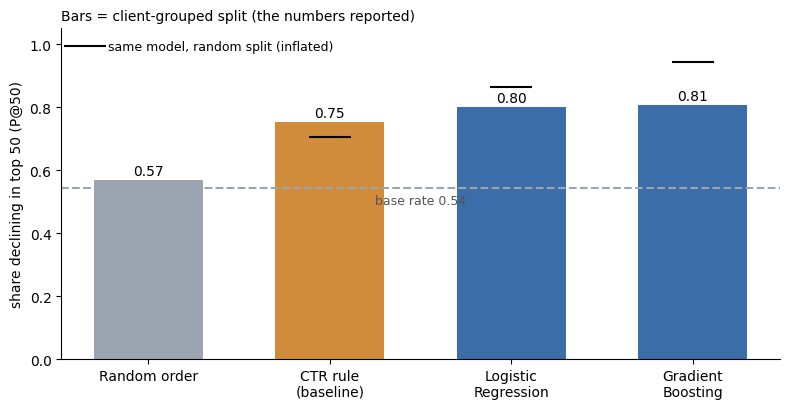

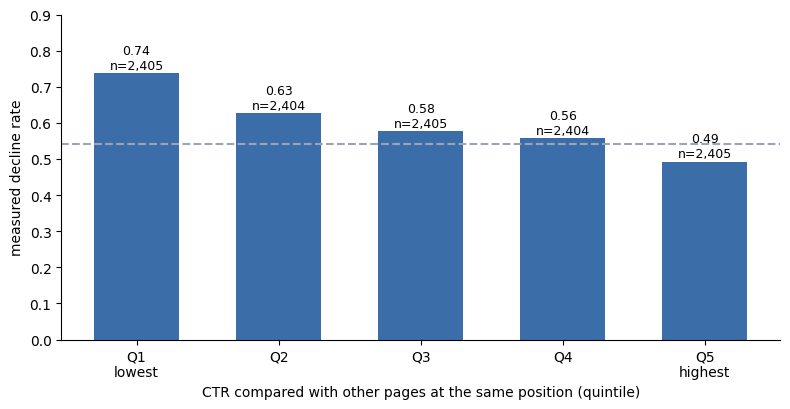

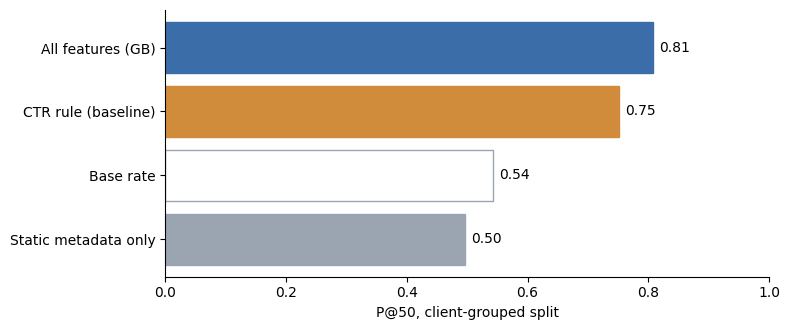

wrote work/figures/paper_fig1..3 and work/outputs/capstone_metrics.json


In [ ]:
import matplotlib.pyplot as plt
os.makedirs("work/figures", exist_ok=True)
os.makedirs("work/outputs", exist_ok=True)
BLUE, GREY, GREEN, ORANGE = "#3B6EA8", "#9AA5B1", "#4E9A6B", "#D08C3A"

# Figure 1 — model vs baseline, same grouped split (+ random-split inflation)
order = ["Dummy (random order)", "Week-4 rule baseline", "Logistic Regression", "Gradient Boosting"]
fig, ax = plt.subplots(figsize=(8, 4.2))
xs = np.arange(len(order))
ax.bar(xs, res.loc[order, "P@50"], color=[GREY, ORANGE, BLUE, BLUE], width=0.6)
ax.scatter(xs[1:], res.loc[order[1:], "P@50 random split"], marker="_", s=900, color="black", zorder=3,
           label="same model, random split (inflated)")
ax.axhline(base, ls="--", color=GREY); ax.text(1.5, base - 0.05, f"base rate {base:.2f}", ha="center", fontsize=9, color="#555")
ax.set_title("Bars = client-grouped split (the numbers reported)", fontsize=10, loc="left")
for x, v in zip(xs, res.loc[order, "P@50"]): ax.text(x, v + 0.015, f"{v:.2f}", ha="center", fontsize=10)
ax.set_xticks(xs, ["Random order", "CTR rule\n(baseline)", "Logistic\nRegression", "Gradient\nBoosting"])
ax.set_ylabel("share declining in top 50 (P@50)"); ax.set_ylim(0, 1.05); ax.legend(loc="upper left", fontsize=9, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("work/figures/paper_fig1_model_vs_baseline.png", dpi=160); plt.show()

# Figure 2 — the signal that holds: CTR relative to position
vis = (df["impressions_90d"] >= 500) & (df["avg_position"] <= 20)
q = pd.qcut(df.loc[vis, "ctr_vs_expected"].rank(method="first"), 5, labels=["Q1\nlowest", "Q2", "Q3", "Q4", "Q5\nhighest"])
t = df[vis].groupby(q, observed=True)["target_decay"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(range(5), t["mean"], color=BLUE, width=0.6)
for i, (m_, n_) in enumerate(zip(t["mean"], t["size"])): ax.text(i, m_ + 0.012, f"{m_:.2f}\nn={n_:,}", ha="center", fontsize=9)
ax.axhline(base, ls="--", color=GREY)
ax.set_xticks(range(5), t.index); ax.set_xlabel("CTR compared with other pages at the same position (quintile)")
ax.set_ylabel("measured decline rate"); ax.set_ylim(0, 0.9); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("work/figures/paper_fig2_ctr_signal.png", dpi=160); plt.show()

# Figure 3 — honesty check: where the skill comes from
labels = ["Static metadata only", "Base rate", "CTR rule (baseline)", "All features (GB)"]
vals = [static_only.loc["Gradient Boosting", "P@50"], base, after.loc["Week-4 rule baseline", "P@50"], after.loc["Gradient Boosting", "P@50"]]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(labels, vals, color=[GREY, "white", ORANGE, BLUE], edgecolor=[GREY, GREY, ORANGE, BLUE])
for i, v in enumerate(vals): ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=10)
ax.set_xlim(0, 1); ax.set_xlabel("P@50, client-grouped split"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("work/figures/paper_fig3_window_check.png", dpi=160); plt.show()

with open("work/outputs/capstone_metrics.json", "w") as f:
    json.dump({"base_rate": round(float(base), 3), "grouped": after[["P@50", "ROC-AUC"]].to_dict(), "random": before[["P@50", "ROC-AUC"]].to_dict(),
               "static_only_gb_p50": float(static_only.loc["Gradient Boosting", "P@50"]),
               "batch_decline_rate": round(float(top["target_decay"].mean()), 3), "seed": SEED}, f, indent=2)
print("wrote work/figures/paper_fig1..3 and work/outputs/capstone_metrics.json")

### Research-page design notes (30 min review)
Looked at: repo paper-examples (three-door example), distill.pub, ourworldindata.org.

- **Key findings first:** OWID opens with short summary boxes → my paper has an abstract box + 4 stat cards at the top.
- **Figures inside the text, each with a caption that states the takeaway** (Distill) → each of my figures has a one-sentence caption.
- **Same evidence, different reader** (paper-examples) → my paper is written for technical reviewers; numbers and limitations would not change for other readers.
- **Easy navigation on long pages** → sticky table of contents on wide screens.
- **Readable on phone and in dark mode** → tested both.
- Could improve: a short "plain-language summary" for non-technical readers.

## 5-minute demo outline (Week-8 showcase)

| Time | Part | What I say / show |
|---|---|---|
| 0:00–0:45 | **Question** | An editor can review ~50 pages a week out of thousands. Which pages should go first? This is FlyRank's Refresh problem: a ranked weekly review queue with a reason and an action for each page. |
| 0:45–2:00 | **Method** | 30,000 pseudonymized pages from 32 clients. Label: impressions fell >20% (last 30d vs previous 30d), base rate 54%. First a transparent baseline (CTR too low for the page's position), then Logistic Regression and Gradient Boosting. Validation grouped by client, so every client is scored by a model that never saw it. Leakage checks, including a deliberate leak to prove the harness catches it. |
| 2:00–3:00 | **One chart** | Figure 1 (model vs baseline): in the top 50, ~81% declining for the models vs 75% for the CTR rule vs 57% for random order. The black ticks show a random split would have inflated this to 0.94. |
| 3:00–4:00 | **One honest result** | The models beat the rule by about 5 points, a modest gain. A model using only static page data scores below the base rate (0.50), so the skill comes from traffic windows that overlap the label: the ranking describes decline already in progress, it does not forecast it. And "refresh old pages" does not hold: older pages declined less. |
| 4:00–5:00 | **One recommendation** | Use it as decision support: a weekly batch of 50 pages (max 10 per client), each with a reason code. Start with visible but under-clicked pages and rewrite the title and meta first. Do not refresh by age alone. Re-validate monthly and fall back to the CTR rule if the batch hit rate drops below 0.75. |

Live paper: https://begs44.github.io/flyrank-ml/

## Shareable cuts

**Social post (methodology)**

Which pages should a content team refresh first? For my FlyRank ML Internship capstone, I ranked 30,000 pseudonymized pages from 32 client sites.

The lesson was in the validation. A random train/test split said my model was right on 94% of its top 50 picks. Splitting by client, so the model is always tested on sites it has never seen, dropped that to 81%, against 75% for a simple "CTR too low for its position" rule. A static-only check also showed the model describes decline already in progress rather than forecasting it, so I present it as decision support, not prediction.

Honest validation is worth more than a big number.
Paper + code: https://begs44.github.io/flyrank-ml/

**Employer summary (3 sentences)**

I built a page-refresh ranking and action playbook that tells a content team which 50 pages to review each week and what to fix on each one. It is trained on real, pseudonymized search data from the FlyRank ML Internship (30,000 pages, 32 client sites), using Logistic Regression and Gradient Boosting with client-grouped cross-validation and leakage checks. It found 81% declining pages in its top 50 against 75% for a transparent CTR rule and 57% at random, and I documented that it describes decline in progress rather than forecasting it.

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
